# 12 — Testes de Hipótese

Ao longo do livro, várias diferenças ficaram sem resposta: a sexta-feira tem **mesmo** mais fumantes, ou foi acaso das 19 mesas? Fumantes dão gorjetas diferentes? Um modelo com 1 ponto a mais de acurácia é **mesmo** melhor?

Um **teste de hipótese** é um procedimento para responder a perguntas desse tipo: **essa diferença é grande demais para ser explicada só pelo acaso?**

Neste notebook vamos:
- Entender a lógica do teste: **hipótese nula**, **estatística de teste** e **p-valor**
- Fazer um **teste de permutação**, construído só com simulação
- Usar o **teste t** e o **teste qui-quadrado**
- Conhecer os **erros tipo I e II** e o **poder** de um teste
- Comparar dois modelos de ML com um **teste pareado**
- Entender o perigo dos **testes múltiplos** e como corrigi-los
- Separar **significância estatística** de **importância prática**

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestIndPower        # cálculo de poder e de tamanho de amostra
from statsmodels.stats.multitest import multipletests    # correções para testes múltiplos

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
gorjetas["percentual"] = gorjetas["tip"] / gorjetas["total_bill"] * 100

## 🎓 Conceito: a lógica de um teste de hipótese

Um teste funciona como um **julgamento**:
1. **Hipótese nula ($H_0$):** a posição "sem novidade", que o réu é inocente. Por exemplo: "fumantes e não fumantes dão, em média, a mesma gorjeta" (a diferença verdadeira é zero).
2. **Hipótese alternativa ($H_1$):** o que suspeitamos: "as gorjetas médias são diferentes".
3. **Estatística de teste:** um número que resume a evidência, como a diferença entre as médias das duas amostras.
4. **Distribuição nula:** como a estatística se comportaria **se $H_0$ fosse verdadeira**, ou seja, só por acaso.
5. **p-valor:** a probabilidade de, **se $H_0$ fosse verdadeira**, obter uma estatística **tão extrema quanto a observada** (ou mais).

Se o p-valor é **pequeno** (abaixo de um limite $\alpha$ escolhido antes, tradicionalmente **0,05**), os dados seriam muito improváveis num mundo sem diferença, e **rejeitamos $H_0$**. Se não, **não rejeitamos** $H_0$.

Atenção à linguagem do julgamento: "não rejeitar $H_0$" é como "**não culpado**", não "inocente". Falta de evidência de uma diferença **não** é evidência de que a diferença é zero.

## 2. Um teste de permutação: fumantes dão gorjetas diferentes?

O **teste de permutação** constrói a distribuição nula sem nenhuma fórmula. A ideia: se $H_0$ é verdadeira, o rótulo "fumante / não fumante" **não tem nada a ver** com a gorjeta. Então podemos **embaralhar** os rótulos ao acaso, recalcular a diferença, e repetir milhares de vezes. Isso mostra que diferenças o puro acaso produz.

Fumantes: 16.32%   não fumantes: 15.93%   diferença: +0.39 pontos
p-valor (permutação): 0.6436


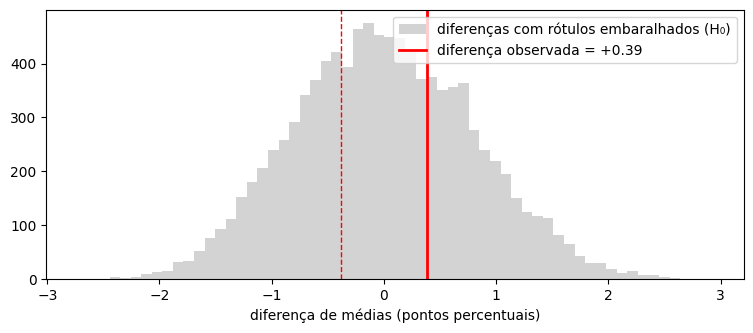

In [2]:
fumante = (gorjetas["smoker"] == "Yes").to_numpy()
percentual = gorjetas["percentual"].to_numpy()

def diferenca_medias(valores, grupo):
    """Média do grupo True menos média do grupo False."""
    return valores[grupo].mean() - valores[~grupo].mean()

observada = diferenca_medias(percentual, fumante)
print(f"Fumantes: {percentual[fumante].mean():.2f}%   não fumantes: {percentual[~fumante].mean():.2f}%   diferença: {observada:+.2f} pontos")

# 10.000 embaralhamentos: rng.permutation devolve uma cópia embaralhada dos rótulos.
nula = np.array([diferenca_medias(percentual, rng.permutation(fumante)) for _ in range(10_000)])
# p-valor BILATERAL: diferenças tão extremas quanto a observada, para qualquer lado.
p_valor = np.mean(np.abs(nula) >= np.abs(observada))
print(f"p-valor (permutação): {p_valor:.4f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(nula, bins=60, color="lightgray", label="diferenças com rótulos embaralhados (H₀)")
ax.axvline(observada, color="red", linewidth=2, label=f"diferença observada = {observada:+.2f}")
ax.axvline(-observada, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("diferença de médias (pontos percentuais)")
ax.legend()
plt.show()

**Conclusão:** os fumantes deram, em média, **0,39 ponto** a mais de gorjeta (16,32% contra 15,93%). Mas, embaralhando os rótulos ao acaso, diferenças desse tamanho aparecem o tempo todo: o histograma cinza (o que o acaso produz) vai de cerca de −3 a +3 pontos, e a diferença observada fica bem no meio dele. O p-valor é **0,64**: em 64% dos embaralhamentos, a diferença foi tão grande quanto a observada ou maior.

**Não rejeitamos $H_0$**: os dados não mostram evidência de que fumantes e não fumantes deem gorjetas diferentes. (E, como lembrado acima, isso não prova que as gorjetas são iguais.)

## 🎓 Conceito: teste t para duas médias

O **teste t** faz a mesma pergunta com uma fórmula. A estatística é a diferença de médias **dividida pelo seu erro padrão** (quantos erros padrão a diferença está de zero):

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}}$$

Pelo TCL, se $H_0$ é verdadeira, $t$ segue aproximadamente uma distribuição t de Student. Esta versão, que não supõe que os dois grupos tenham a mesma variância, é o **teste t de Welch** (`equal_var=False`), a escolha mais segura.

O teste t supõe que as **médias** são aproximadamente normais, o que o TCL garante com amostras razoáveis, a menos que haja caudas pesadas (notebook 10). O teste de permutação não precisa dessa suposição.

In [3]:
# À mão, para ver a fórmula funcionando.
a, b = percentual[fumante], percentual[~fumante]
ep = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
t_mao = (a.mean() - b.mean()) / ep
print(f"t à mão: {t_mao:.4f}")

resultado = stats.ttest_ind(a, b, equal_var=False)
print(f"scipy (Welch): t = {resultado.statistic:.4f}, p-valor = {resultado.pvalue:.4f}")

# Repetindo SEM a mesa de 71% (um fumante): a conclusão muda?
sem_outlier = percentual < 70
r2 = stats.ttest_ind(percentual[fumante & sem_outlier], percentual[~fumante & sem_outlier], equal_var=False)
print(f"Sem a mesa de 71%: diferença = {diferenca_medias(percentual[sem_outlier], fumante[sem_outlier]):+.2f}, t = {r2.statistic:.3f}, p-valor = {r2.pvalue:.4f}")
# O teste de Mann-Whitney compara os POSTOS (como o Spearman do notebook 04), e é robusto a outliers.
print(f"Mann-Whitney (com todas as mesas): p-valor = {stats.mannwhitneyu(a, b).pvalue:.4f}")

t à mão: 0.4112
scipy (Welch): t = 0.4112, p-valor = 0.6817
Sem a mesa de 71%: diferença = -0.21, t = -0.283, p-valor = 0.7776
Mann-Whitney (com todas as mesas): p-valor = 0.5607


**Conclusão:** o $t$ calculado à mão (**0,411**) bate com o do scipy, e o p-valor do teste t (**0,68**) leva à mesma conclusão do teste de permutação (0,64). Os dois p-valores não são idênticos porque usam caminhos diferentes (fórmula com a t × simulação), mas contam a mesma história.

A conclusão também é **robusta**: sem a mesa de 71% (de um fumante), a diferença até muda de sinal (**−0,21** ponto) e o p-valor fica em 0,78; o teste de Mann-Whitney, que compara postos e ignora a magnitude dos outliers, dá **0,56**. Por qualquer caminho, não há evidência de diferença.

## 🎓 Conceito: erros tipo I e tipo II, e o poder do teste

Um teste pode errar de duas formas:

| | $H_0$ verdadeira (sem efeito) | $H_0$ falsa (há efeito) |
|---|---|---|
| **Rejeitamos $H_0$** | ❌ **Erro tipo I** (falso positivo), probabilidade $\alpha$ | ✅ acerto: o **poder** do teste |
| **Não rejeitamos $H_0$** | ✅ acerto | ❌ **Erro tipo II** (falso negativo), probabilidade $\beta$ |

- O nível $\alpha$ (0,05) é escolhido por nós: é a taxa de alarmes falsos que aceitamos **quando não há efeito nenhum**.
- O **poder** ($1 - \beta$) é a chance de detectar um efeito **que existe**. Ele aumenta com o **tamanho do efeito** e com o **tamanho da amostra**, e diminui com a dispersão dos dados.

A tabela é a mesma **matriz de confusão** do ML-02: o teste é um "classificador" de hipóteses, $\alpha$ é a taxa de falsos positivos e o poder é o **recall**.

Sem efeito:       4.6% dos testes rejeitam H₀ (erro tipo I; esperado: 5%)
Efeito de 0,5 σ:  48.4% dos testes rejeitam H₀ (poder)


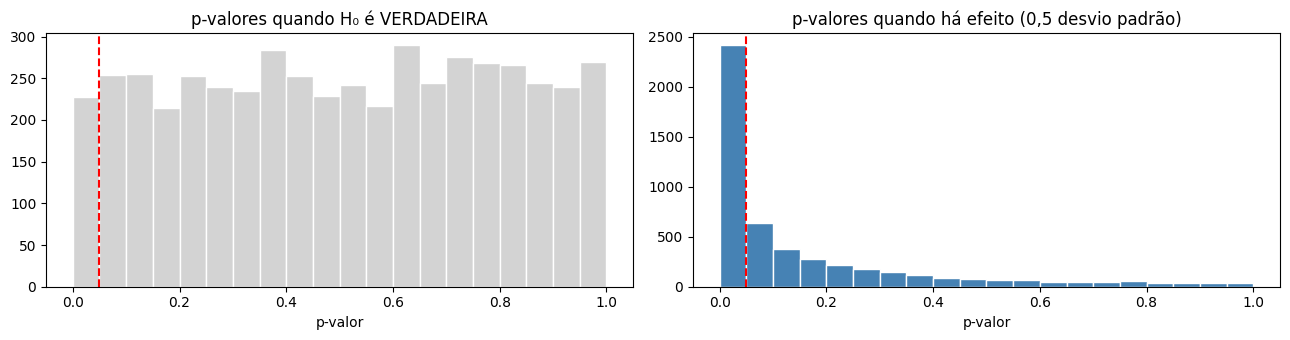

In [4]:
def simular_testes(efeito, n, repeticoes=5_000):
    """Simula muitos estudos com dois grupos normais (desvio 1) cuja diferença verdadeira é 'efeito'. Devolve os p-valores."""
    g1 = rng.normal(0, 1, size=(repeticoes, n))
    g2 = rng.normal(efeito, 1, size=(repeticoes, n))
    return stats.ttest_ind(g1, g2, axis=1, equal_var=False).pvalue   # axis=1: um teste por linha


p_sem_efeito = simular_testes(efeito=0, n=30)
p_com_efeito = simular_testes(efeito=0.5, n=30)
print(f"Sem efeito:       {np.mean(p_sem_efeito < 0.05):.1%} dos testes rejeitam H₀ (erro tipo I; esperado: 5%)")
print(f"Efeito de 0,5 σ:  {np.mean(p_com_efeito < 0.05):.1%} dos testes rejeitam H₀ (poder)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(p_sem_efeito, bins=20, range=(0, 1), color="lightgray", edgecolor="white")
axes[0].set_title("p-valores quando H₀ é VERDADEIRA")
axes[1].hist(p_com_efeito, bins=20, range=(0, 1), color="steelblue", edgecolor="white")
axes[1].set_title("p-valores quando há efeito (0,5 desvio padrão)")
for ax in axes:
    ax.axvline(0.05, color="red", linestyle="--")
    ax.set_xlabel("p-valor")
plt.tight_layout()
plt.show()

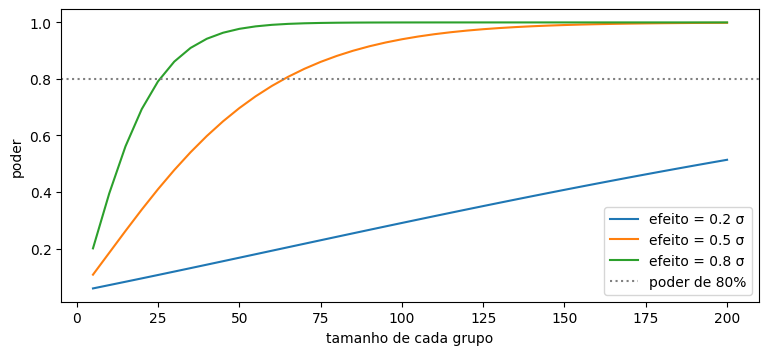

Para detectar um efeito de 0.2 σ com 80% de poder: 394 por grupo
Para detectar um efeito de 0.5 σ com 80% de poder: 64 por grupo
Para detectar um efeito de 0.8 σ com 80% de poder: 26 por grupo


In [5]:
# Poder em função do tamanho da amostra (por grupo), para três tamanhos de efeito.
analise = TTestIndPower()
tamanhos = np.arange(5, 201, 5)
fig, ax = plt.subplots(figsize=(9, 3.8))
for efeito in [0.2, 0.5, 0.8]:
    # effect_size é a diferença de médias em desvios padrão (o "d de Cohen").
    ax.plot(tamanhos, analise.power(effect_size=efeito, nobs1=tamanhos, alpha=0.05), label=f"efeito = {efeito} σ")
ax.axhline(0.8, color="gray", linestyle=":", label="poder de 80%")
ax.set_xlabel("tamanho de cada grupo")
ax.set_ylabel("poder")
ax.legend()
plt.show()

for efeito in [0.2, 0.5, 0.8]:
    n_necessario = analise.solve_power(effect_size=efeito, power=0.8, alpha=0.05)
    print(f"Para detectar um efeito de {efeito} σ com 80% de poder: {np.ceil(n_necessario):.0f} por grupo")

**Conclusão:** quando $H_0$ é verdadeira, os p-valores se espalham **uniformemente** entre 0 e 1 (histograma cinza), e **4,6%** deles caem abaixo de 0,05 só por acaso, perto dos 5% prometidos por $\alpha$. Quando há um efeito de 0,5 desvio padrão, os p-valores se amontoam perto de zero, mas com 30 pessoas por grupo o teste detecta o efeito em apenas **48,4%** das vezes. Em mais da metade dos estudos, um efeito real passaria despercebido.

As curvas de poder mostram o tamanho de amostra necessário para 80% de poder: **26 por grupo** para um efeito grande (0,8 σ), **64** para um médio (0,5 σ) e **394** para um pequeno (0,2 σ). Efeitos pequenos exigem amostras enormes.

Isso ajuda a ler o resultado dos fumantes: com ~90 fumantes e ~150 não fumantes, um efeito pequeno poderia facilmente passar despercebido. "Não detectamos" não significa "não existe".

## 🎓 Conceito: teste qui-quadrado de independência

Para duas variáveis **categóricas**, a pergunta é: elas são independentes? No notebook 06, calculamos a tabela **esperada sob independência** para dia × fumantes. O **teste qui-quadrado** mede a distância entre o observado ($O$) e o esperado ($E$):

$$\chi^2 = \sum_{\text{células}} \frac{(O - E)^2}{E}$$

Se as variáveis forem independentes, $\chi^2$ segue (aproximadamente) a distribuição **qui-quadrado** com $(\text{linhas} - 1)(\text{colunas} - 1)$ graus de liberdade. Uma regra prática: a aproximação é boa quando todas as contagens esperadas são de pelo menos 5.

In [6]:
tabela = pd.crosstab(gorjetas["day"], gorjetas["smoker"])
qui2, p, gl, esperado = stats.chi2_contingency(tabela)

# À mão, a partir do esperado que o scipy devolveu.
qui2_mao = np.sum((tabela.to_numpy() - esperado) ** 2 / esperado)
print(f"χ² à mão = {qui2_mao:.3f}   scipy = {qui2:.3f}   graus de liberdade = {gl}   p-valor = {p:.2e}")   # .2e = notação científica
print(f"Menor contagem esperada: {esperado.min():.1f}")

# Quais células contribuem mais? Os "resíduos" (O - E) / √E mostram onde estão as maiores diferenças.
residuos = (tabela - esperado) / np.sqrt(esperado)
residuos.round(2)

χ² à mão = 25.787   scipy = 25.787   graus de liberdade = 3   p-valor = 1.06e-05
Menor contagem esperada: 7.2


smoker,Yes,No
day,,
Thur,-1.36,1.07
Fri,2.88,-2.26
Sat,1.54,-1.20
Sun,-1.85,1.45


**Conclusão:** o $\chi^2$ calculado à mão e o do scipy batem (**25,79**, com 3 graus de liberdade), e o p-valor é **0,00001**: se dia e fumantes fossem independentes, uma tabela tão diferente da esperada seria raríssima. **Rejeitamos a independência.** A menor contagem esperada é 7,2, acima de 5, então a aproximação do teste é confiável.

Os resíduos mostram de onde vem a diferença: a **sexta** tem muito mais fumantes que o esperado (resíduo **+2,88**), e o **domingo** tem menos (**−1,85**). Isso confirma, agora com um teste formal, o que os intervalos de Wilson do notebook 11 sugeriam.

(Um cuidado: os dados vêm de um único garçom num único restaurante. O teste diz que a associação dificilmente é acaso **nessa amostra**, não que vale para todos os restaurantes, e muito menos **por que** ela existe.)

## 3. Comparando dois modelos: o teste pareado

No ML, é comum comparar dois modelos pelas pontuações nas **mesmas** dobras da validação cruzada. As pontuações dos dois modelos **não são independentes**: uma dobra "difícil" derruba os dois ao mesmo tempo. O **teste t pareado** usa isso a seu favor: ele analisa a **diferença dobra a dobra**, eliminando a variação que vem da dificuldade de cada dobra.

Vamos simular 10 dobras em que o modelo B é, de verdade, 0,5 ponto melhor que o A, mas a dificuldade das dobras varia bastante.

In [7]:
dificuldade = rng.normal(0, 2.0, size=10)                      # algumas dobras são mais difíceis que outras
modelo_a = 85.0 + dificuldade + rng.normal(0, 0.4, size=10)
modelo_b = 85.5 + dificuldade + rng.normal(0, 0.4, size=10)
print(pd.DataFrame({"A": modelo_a, "B": modelo_b, "B - A": modelo_b - modelo_a}).round(2).T)

independente = stats.ttest_ind(modelo_b, modelo_a, equal_var=False)
pareado = stats.ttest_rel(modelo_b, modelo_a)                   # rel = "related", o teste pareado
print(f"\nDiferença média: {np.mean(modelo_b - modelo_a):.2f} pontos")
print(f"Teste t para amostras independentes: p-valor = {independente.pvalue:.4f}")
print(f"Teste t pareado:                     p-valor = {pareado.pvalue:.4f}")

           0      1      2      3      4      5      6      7      8      9
A      83.76  87.70  84.14  86.33  81.39  83.86  82.99  85.48  85.12  84.72
B      84.58  88.21  84.48  86.62  82.02  84.99  82.22  86.06  85.37  86.03
B - A   0.82   0.51   0.35   0.30   0.64   1.12  -0.77   0.57   0.26   1.31

Diferença média: 0.51 pontos
Teste t para amostras independentes: p-valor = 0.5406
Teste t pareado:                     p-valor = 0.0196


**Conclusão:** o modelo B ganhou em **9 das 10 dobras**, com uma diferença média de **0,51 ponto**. Mesmo assim, o teste para amostras independentes dá p-valor **0,54**: comparando as duas colunas como se não tivessem relação, a enorme variação entre dobras (de ~81 a ~88) esconde a diferença. O teste **pareado** olha só para a coluna "B − A", que varia pouco, e dá p-valor **0,02**: há evidência de que B é melhor.

🔗 **Ponte para o ML:** ao comparar modelos com validação cruzada, use **as mesmas dobras** para todos (como fizemos com o `random_state` fixo no ML-01 e no ML-02) e compare as **diferenças** dobra a dobra. Um cuidado extra: as dobras compartilham dados de treino, então o teste pareado comum é um pouco otimista; existem versões corrigidas (como o teste de Nadeau e Bengio), mas a ideia de parear continua sendo a principal.

## 🎓 Conceito: testes múltiplos

Cada teste com $\alpha = 0{,}05$ tem 5% de chance de um falso positivo. Mas se fizermos **muitos** testes, os falsos positivos se acumulam: com 20 testes independentes, todos sem efeito nenhum, a chance de **pelo menos um** dar "significativo" é $1 - 0{,}95^{20} \approx 64\%$. É o problema do aniversário (notebook 05) de novo: muitas oportunidades tornam alguma coincidência quase certa.

Duas correções populares:
- **Bonferroni:** usa $\alpha / m$ para cada um dos $m$ testes. Simples e muito conservadora.
- **Benjamini-Hochberg (BH):** controla a **taxa de falsas descobertas** (FDR), a proporção esperada de falsos positivos entre os resultados declarados significativos. Mais poderosa quando há muitos testes.

In [8]:
# 1.000 "estudos", cada um com 20 testes sobre dados sem nenhum efeito.
estudos_com_algum = 0
for _ in range(1_000):
    p_valores = stats.ttest_ind(rng.normal(size=(20, 30)), rng.normal(size=(20, 30)), axis=1).pvalue
    estudos_com_algum += np.any(p_valores < 0.05)
print(f"Estudos com pelo menos um 'achado' falso: {estudos_com_algum / 1_000:.1%}   (teoria: {1 - 0.95**20:.1%})")

# Um cenário misto: 100 testes, dos quais 10 têm efeito real (0,8 σ) e 90 não têm.
efeitos = np.array([0.8] * 10 + [0.0] * 90)
p_valores = np.array([stats.ttest_ind(rng.normal(0, 1, 30), rng.normal(e, 1, 30)).pvalue for e in efeitos])
real = efeitos > 0

linhas = []
for nome, rejeita in [("sem correção", p_valores < 0.05),
                      ("Bonferroni", multipletests(p_valores, alpha=0.05, method="bonferroni")[0]),
                      ("Benjamini-Hochberg", multipletests(p_valores, alpha=0.05, method="fdr_bh")[0])]:
    linhas.append({"correção": nome, "descobertas": rejeita.sum(),
                   "verdadeiras": (rejeita & real).sum(), "falsas": (rejeita & ~real).sum()})
pd.DataFrame(linhas).set_index("correção")

Estudos com pelo menos um 'achado' falso: 63.3%   (teoria: 64.2%)


,descobertas,verdadeiras,falsas
correção,,,
sem correção,12,8,4
Bonferroni,2,2,0
Benjamini-Hochberg,5,5,0


**Conclusão:** a simulação confirma a teoria: **63,3%** dos estudos com 20 testes sobre dados **sem nenhum efeito** encontraram pelo menos um resultado "significativo" (a teoria diz 64,2%).

No cenário com 10 efeitos reais em 100 testes:
- **Sem correção**, declaramos 12 descobertas, mas **4 são falsas** (um terço de tudo o que "descobrimos").
- **Bonferroni** elimina os falsos positivos, mas é tão rigorosa que só encontra **2** dos 10 efeitos reais.
- **Benjamini-Hochberg** também não tem nenhum falso positivo aqui e encontra **5** efeitos reais, mais que o dobro do Bonferroni.

É a troca entre precisão e recall do ML-02 aparecendo de novo: corrigir mais protege contra alarmes falsos, mas deixa passar efeitos reais.

## 4. Significância estatística não é importância prática

O p-valor depende do **tamanho da amostra**. Com dados suficientes, **qualquer** diferença, por menor que seja, vira "estatisticamente significativa". Por isso, sempre reporte o **tamanho do efeito** (e o seu intervalo de confiança), e não só o p-valor.

In [9]:
# Dois grupos cuja média verdadeira difere em 0,02 desvio padrão: uma diferença irrelevante na prática.
for n in [100, 10_000, 1_000_000]:
    g1 = rng.normal(0, 1, n)
    g2 = rng.normal(0.02, 1, n)
    teste = stats.ttest_ind(g2, g1)
    n_texto = f"{n:_}".replace("_", ".")   # separador de milhares com ponto
    print(f"n = {n_texto:>9} por grupo: diferença = {g2.mean() - g1.mean():+.4f}, p-valor = {teste.pvalue:.2e}")

n =       100 por grupo: diferença = -0.0486, p-valor = 7.09e-01
n =    10.000 por grupo: diferença = +0.0245, p-valor = 8.34e-02
n = 1.000.000 por grupo: diferença = +0.0209, p-valor = 2.82e-49


**Conclusão:** a diferença verdadeira é sempre a mesma, insignificante (0,02 desvio padrão). Com **100** pessoas por grupo, o p-valor é 0,71; com **10.000**, 0,08; e com **1 milhão**, o p-valor é **2,8 × 10⁻⁴⁹**, um número "impressionante" para uma diferença que ninguém notaria na prática.

O p-valor responde "**existe** alguma diferença?", e com dados suficientes a resposta é quase sempre "sim". A pergunta que importa costuma ser "**de que tamanho** é a diferença?", e quem responde é a estimativa do efeito com o seu intervalo de confiança (notebook 11). Com bases de dados grandes, comuns em ML, isso é especialmente importante.

## 🎓 Conceito: o que o p-valor NÃO é

Erros de interpretação muito comuns:
- ❌ "O p-valor é a probabilidade de $H_0$ ser verdadeira." **Não**: ele é calculado **supondo** $H_0$ verdadeira. A probabilidade de $H_0$ dado os dados é uma pergunta bayesiana (notebooks 06 e 16), e confundir as duas é o mesmo erro de $P(A \mid B)$ com $P(B \mid A)$.
- ❌ "p = 0,04 é uma descoberta; p = 0,06 não é nada." A diferença entre os dois é minúscula; 0,05 é uma convenção, não uma fronteira mágica.
- ❌ "p > 0,05 prova que não há diferença." Pode ser só falta de poder (amostra pequena).
- ❌ "p-valor pequeno = efeito grande." Vimos acima que não.
- ❌ Testar várias coisas e reportar só as "significativas" (*p-hacking*). É o problema dos testes múltiplos disfarçado.

## 5. Resumo e próximos passos

| Pergunta | Teste | `scipy.stats` |
|---|---|---|
| duas médias, grupos independentes | t de Welch (ou permutação) | `ttest_ind(equal_var=False)`, `permutation_test` |
| duas médias, dados pareados | t pareado | `ttest_rel` |
| dois grupos, robusto a outliers | Mann-Whitney | `mannwhitneyu` |
| duas variáveis categóricas | qui-quadrado | `chi2_contingency` |

**Conceitos que você aprendeu**
- **Hipótese nula e alternativa**, **estatística de teste**, **distribuição nula** e **p-valor**.
- O **teste de permutação**, que constrói a distribuição nula embaralhando rótulos.
- **Teste t** (Welch e pareado), **Mann-Whitney** e **qui-quadrado**.
- **Erros tipo I e II**, **poder** e o cálculo do **tamanho de amostra**.
- **Testes múltiplos** e as correções de **Bonferroni** e **Benjamini-Hochberg**.
- **Significância estatística ≠ importância prática**, e o que o p-valor não é.

🔗 **Ponte para o ML:** testes A/B de modelos em produção são testes de hipótese; comparar modelos nas mesmas dobras pede um teste **pareado**; e testar dezenas de modelos e hiperparâmetros e escolher o melhor é um problema de **testes múltiplos**, a "maldição do vencedor" do ML-01. A solução de lá, o **conjunto de teste guardado até o fim**, é justamente uma proteção contra isso.

**Python novo:** `rng.permutation`, `stats.ttest_ind` / `ttest_rel` / `mannwhitneyu` / `chi2_contingency`, `axis=1` em testes, `TTestIndPower` (`.power`, `.solve_power`), `multipletests`, `np.ceil`, `np.any`, formato `.2e`.

**Próximo notebook:** vários métodos deste livro "escolhem os parâmetros que melhor explicam os dados": o `.fit` do notebook 08, a regressão logística, as redes neurais. No notebook 13 vamos ver o princípio por trás de todos eles: a **máxima verossimilhança**, e descobrir por que a regressão linear usa o erro quadrático e a logística usa a log loss.